# Sensitivity to the weather lag window

Compare 1–30 weather input days for the hybrid model and the air-temperature-only
model. The nine-day reference includes the current day and eight preceding days.

Evaluate each member's final weights on its original chronological training and
validation splits with its baseline rebuilt by native inference. Compute mean
squared error (MSE) between predicted and registered national death counts at
daily and weekly resolution on each split.

The hybrid sweep uses air temperature and dew point and the weather-only sweep
uses air temperature. Compare changes with lag within each setup. Full execution
evaluates 600 checkpoints and is intended for HPC.

In [1]:
from importlib.util import module_from_spec, spec_from_file_location
from pathlib import Path
import sys

cwd = Path.cwd()
repo = next(
    (
        path for path in (cwd, *cwd.parents)
        if (path / "configs" / "training.example.yaml").is_file()
    ),
    None,
)
if repo is None:
    raise FileNotFoundError("Open the notebook from the sari-weather-mortality checkout.")

sys.path.insert(0, str(repo))
sys.path.insert(0, str(repo / "src"))

import matplotlib.pyplot as plt
import pandas as pd

# Load helpers from this checkout even if Jupyter cached another notebooks package.
utils_path = repo / "notebooks" / "utils.py"
spec = spec_from_file_location("sari_notebook_utils", utils_path)
notebook_utils = module_from_spec(spec)
spec.loader.exec_module(notebook_utils)

ensemble = notebook_utils.ensemble
DEVICE = notebook_utils.DEVICE

from sari_t.aggregation import aggregate_mortality
from sari_t.inference import InferenceModel
from sari_t.run.checkpoint import load_checkpoint, load_run_config, restore_predictor
from sari_t.metrics import calculate_national_mse

## Load models for inspection

The next cell loads member 000 for the selected window from each setup onto CPU.
Inspect `model` for the hybrid predictor or `models[setup]` for another predictor.

In [2]:
inspection_member = 0
inspection_window = 9
setups = {
    "Hybrid (temperature + dew point)": "temperature_kernel_hybrid",
    "Weather only (temperature)": "temperature_kernel_weather_only",
}
windows = range(1, 31)
sweeps = {}
for label, group in setups.items():
    runs = {}
    for run in sorted((repo / "runtime" / "training" / "sets" / group).iterdir()):
        run = run.resolve()
        config = load_run_config(run / "config.yaml")
        lag = config.model_config.kernel_T_days
        if lag in runs:
            raise ValueError(f"Multiple {lag}-day runs in {group}")
        paths = [run / "checkpoints" / f"final_{member:03d}.pt" for member in range(10)]
        if not all(path.is_file() for path in paths):
            raise FileNotFoundError(f"Incomplete ensemble for {run}")
        runs[lag] = (config, paths)
    if set(runs) != set(windows):
        raise ValueError(f"{group} must contain one run for each window in {list(windows)}")
    sweeps[label] = runs

models = {
    label: restore_predictor(
        load_checkpoint(runs[inspection_window][1][inspection_member]), device="cpu",
    ).eval()
    for label, runs in sweeps.items()
}
model = models["Hybrid (temperature + dew point)"]
model

MortalityPredictor(
  (effect_model): ExponentialMortalityModel(
    (batch_norm): LazyBatchNorm1d(0, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (conv1): LazyConv1d(0, 128, kernel_size=(9,), stride=(1,))
    (fc): LinearPos(in_features=128, out_features=30, bias=True)
    (sari_conv): Conv1dPos(15, 30, kernel_size=(10,), stride=(1,), groups=15, bias=False)
    (covid_conv): Conv1dPos(15, 30, kernel_size=(10,), stride=(1,), groups=15, bias=False)
  )
)

## Recompute training and validation MSE

In [3]:
from datetime import timedelta

def split_mse(workspace, result):
    period = workspace.period
    training_end = period.start_date + timedelta(days=training_days - 1)
    validation_start = training_end + timedelta(days=1)
    metrics = {}
    for split, start, end in (
        ("Training", period.start_date, training_end),
        ("Validation", validation_start, period.end_date),
    ):
        offset = (start - period.start_date).days
        count = (end - start).days + 1
        counts = result.predictions.total_deaths[offset:offset + count]
        labels = select_mortality_labels(result.labels, PredictionPeriod(start, end))
        terms = calculate_national_mse(aggregate_mortality(counts), labels)
        metrics.update({(split, term): value for term, value in terms.items()})
    return metrics

from sari_t.data.training_inputs import select_mortality_labels
from sari_t.models.config import PredictionPeriod

rows = []
expected_split = None
for setup, runs in sweeps.items():
    for lag in windows:
        config, paths = runs[lag]
        weeks = ((config.period.end_date - config.period.start_date).days + 1) // 7
        validation_weeks = int(weeks * config.training_config.validation_fraction)
        if not 0 < validation_weeks < weeks:
            raise ValueError(f"{setup}, {lag} days has no usable training/validation split")
        training_days = 7 * (weeks - validation_weeks)
        split_key = (config.period, training_days)
        if expected_split is None:
            expected_split = split_key
        elif split_key != expected_split:
            raise ValueError("All lag runs must use the same training and validation dates.")

        print(f"{setup}, {lag} input days", flush=True)
        inference_model = InferenceModel.from_checkpoint(
            paths[0], data_config=config.data_config, period=config.period, device=DEVICE,
        )
        values = ensemble(inference_model, paths, split_mse, keep_members=True)
        for (split, term), member_mse in values.items():
            rows.extend((setup, lag, member, split, term.removesuffix("_mse").capitalize(), value)
                        for member, value in enumerate(member_mse.tolist()))
        del inference_model

mse_by_member = pd.DataFrame(rows, columns=["Setup", "Window (days)", "Member",
                                              "Split", "Frequency", "MSE"])
mse_by_window = mse_by_member.groupby(["Setup", "Window (days)", "Split", "Frequency"])[
    "MSE"
].agg(["mean", "min", "max"]).reset_index()
mse_by_window

Hybrid (temperature + dew point), 1 input days
Hybrid (temperature + dew point), 2 input days
Hybrid (temperature + dew point), 3 input days
Hybrid (temperature + dew point), 4 input days
Hybrid (temperature + dew point), 5 input days
Hybrid (temperature + dew point), 6 input days
Hybrid (temperature + dew point), 7 input days
Hybrid (temperature + dew point), 8 input days
Hybrid (temperature + dew point), 9 input days
Hybrid (temperature + dew point), 10 input days
Hybrid (temperature + dew point), 11 input days
Hybrid (temperature + dew point), 12 input days
Hybrid (temperature + dew point), 13 input days
Hybrid (temperature + dew point), 14 input days
Hybrid (temperature + dew point), 15 input days
Hybrid (temperature + dew point), 16 input days
Hybrid (temperature + dew point), 17 input days
Hybrid (temperature + dew point), 18 input days
Hybrid (temperature + dew point), 19 input days
Hybrid (temperature + dew point), 20 input days
Hybrid (temperature + dew point), 21 input days
H

,Setup,Window (days),Split,Frequency,mean,min,max
0,Hybrid (temperature + dew point),1,Training,Daily,1.091098e+04,1.090188e+04,1.091573e+04
1,Hybrid (temperature + dew point),1,Training,Weekly,2.613602e+05,2.610873e+05,2.614861e+05
2,Hybrid (temperature + dew point),1,Validation,Daily,1.300330e+04,1.296214e+04,1.303563e+04
3,Hybrid (temperature + dew point),1,Validation,Weekly,3.367918e+05,3.355680e+05,3.379048e+05
4,Hybrid (temperature + dew point),2,Training,Daily,9.329499e+03,9.316094e+03,9.350050e+03
...,...,...,...,...,...,...,...
235,Weather only (temperature),29,Validation,Weekly,1.085680e+06,1.083416e+06,1.088070e+06
236,Weather only (temperature),30,Training,Daily,2.072109e+04,2.068882e+04,2.073921e+04
237,Weather only (temperature),30,Training,Weekly,8.340560e+05,8.327049e+05,8.347246e+05
238,Weather only (temperature),30,Validation,Daily,2.670269e+04,2.663165e+04,2.676291e+04


## Daily and weekly mortality MSE across lag windows

Each column shows one model. Training and validation curves share each panel. Lines show mean MSE across ensemble members, with shading from the lowest to highest member MSE. The dotted reference line marks nine weather input days.

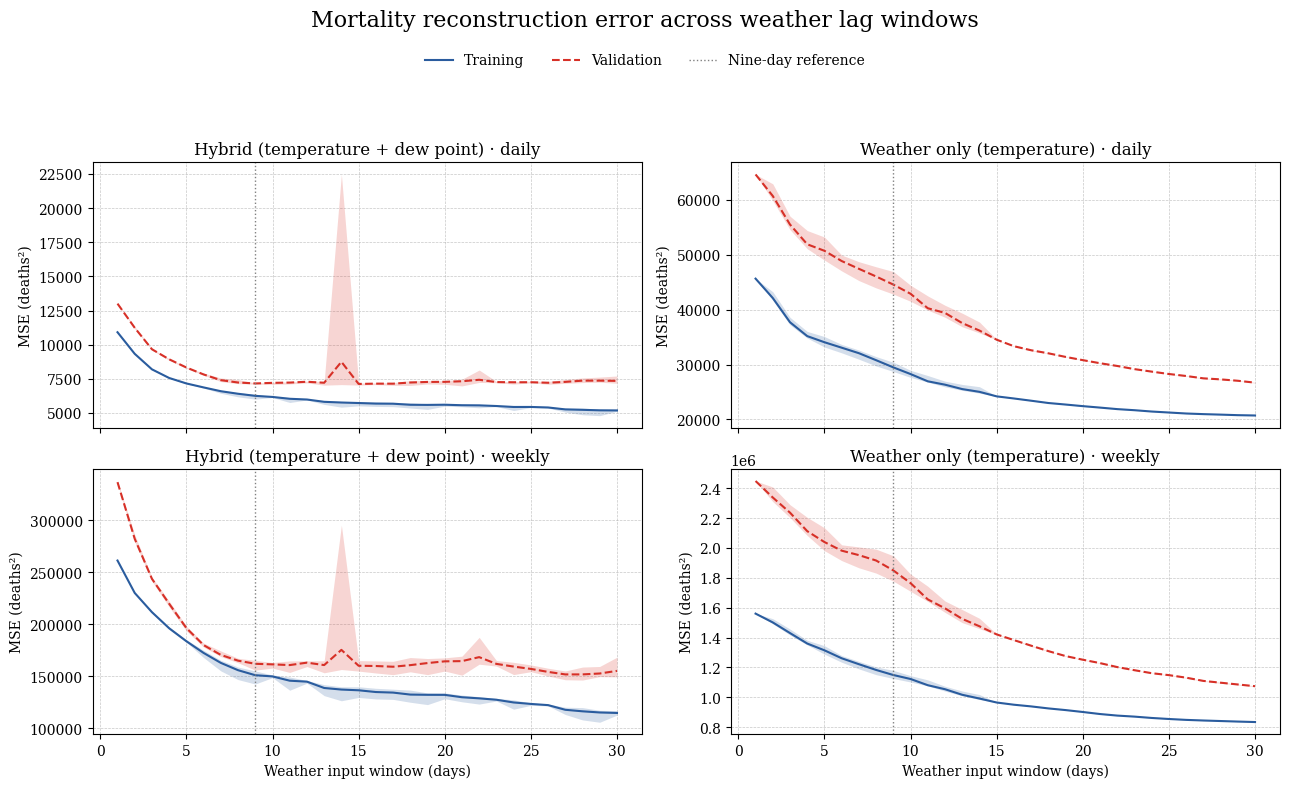

In [4]:
with plt.rc_context({"font.family": "DejaVu Serif", "axes.axisbelow": True}):
    fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharex=True)
    split_styles = {
        "Training": ("#2A5C9E", "-"),
        "Validation": ("#D73027", "--"),
    }
    for col, setup in enumerate(setups):
        for row, frequency in enumerate(("Daily", "Weekly")):
            ax = axes[row, col]
            selected = mse_by_window.query("Setup == @setup and Frequency == @frequency")
            for split, (color, linestyle) in split_styles.items():
                group = selected.loc[selected["Split"] == split].sort_values("Window (days)")
                x = group["Window (days)"].to_numpy()
                ax.plot(x, group["mean"], color=color, linestyle=linestyle,
                        linewidth=1.5, label=split)
                ax.fill_between(x, group["min"], group["max"], color=color,
                                alpha=0.2, linewidth=0)
            ax.axvline(9, color="0.5", linestyle=":", linewidth=1, label="Nine-day reference")
            ax.set_title(f"{setup} · {frequency.lower()}")
            ax.set_ylabel("MSE (deaths²)")
            ax.grid(True, linestyle="--", linewidth=0.5, alpha=0.7)
            if row == 1:
                ax.set_xlabel("Weather input window (days)")

    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.suptitle("Mortality reconstruction error across weather lag windows", fontsize=16)
    fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.94),
               ncol=3, frameon=False)
    fig.tight_layout(rect=(0, 0, 1, 0.88))
    plt.show()